In [59]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
from itertools import cycle
import math
import seaborn as sns

data_dir = Path("data/cluster_chain_n4_e-4.0000/")

instances = pd.read_csv(data_dir / "instances.csv")
instances

,Unnamed: 0,lambda,n_updates,h_file,start_temp,end_temp,trial,out_file
0,0,0.5,1000,instances/cluster_chain_n4_e-4.0000.txt,10.0,0.1,0,data/cluster_chain_n4_e-4.0000/out_l0.5_s10.0_...
1,1,0.5,1000,instances/cluster_chain_n4_e-4.0000.txt,10.0,0.1,1,data/cluster_chain_n4_e-4.0000/out_l0.5_s10.0_...
2,2,0.5,1000,instances/cluster_chain_n4_e-4.0000.txt,10.0,0.1,2,data/cluster_chain_n4_e-4.0000/out_l0.5_s10.0_...
3,3,0.5,1000,instances/cluster_chain_n4_e-4.0000.txt,10.0,0.1,3,data/cluster_chain_n4_e-4.0000/out_l0.5_s10.0_...
4,4,0.5,1000,instances/cluster_chain_n4_e-4.0000.txt,10.0,0.1,4,data/cluster_chain_n4_e-4.0000/out_l0.5_s10.0_...
...,...,...,...,...,...,...,...,...
295,295,2.0,1000,instances/cluster_chain_n4_e-4.0000.txt,10.0,0.1,95,data/cluster_chain_n4_e-4.0000/out_l2.0_s10.0_...
296,296,2.0,1000,instances/cluster_chain_n4_e-4.0000.txt,10.0,0.1,96,data/cluster_chain_n4_e-4.0000/out_l2.0_s10.0_...
297,297,2.0,1000,instances/cluster_chain_n4_e-4.0000.txt,10.0,0.1,97,data/cluster_chain_n4_e-4.0000/out_l2.0_s10.0_...
298,298,2.0,1000,instances/cluster_chain_n4_e-4.0000.txt,10.0,0.1,98,data/cluster_chain_n4_e-4.0000/out_l2.0_s10.0_...


skipping row
skipping row
skipping row
skipping row
skipping row
skipping row
skipping row
skipping row
skipping row
skipping row
skipping row
skipping row
skipping row
skipping row
skipping row
skipping row
skipping row
skipping row
skipping row
skipping row
skipping row
skipping row


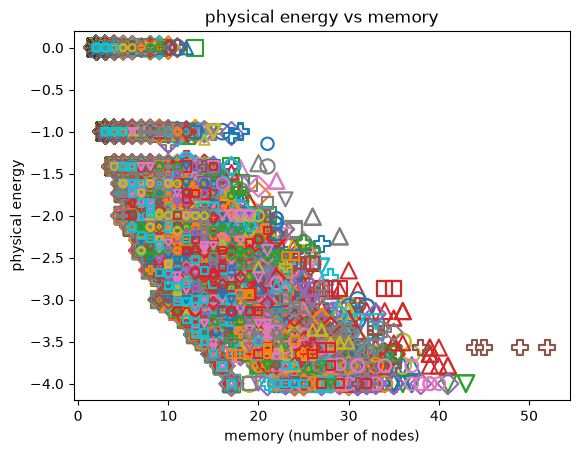

In [91]:
markers = cycle(["o", "s", "^", "D", "v", "P"])
# Scales marker area (points^2) from outer ring to inner ring based on series count
sizes = np.linspace(150, 25, len(instances))

fig, ax = plt.subplots()

final_states = []

for i, (index, row) in enumerate(instances.iterrows()):
    if not Path(row["out_file"]).exists():
        print("skipping row")
        continue

    # this_data = pd.read_csv(row["out_file"]).drop_duplicates(["memory", "energy"])
    this_data = pd.read_csv(row["out_file"])
    color = f"C{i % 10}"  # Explicitly grab Matplotlib's default color cycle

    ax.scatter(
        this_data["memory"],
        this_data["energy"],
        s=sizes[i],
        marker=next(markers),
        facecolors="none",
        edgecolors=color,
        linewidths=1.5,
        label=f"$\\lambda = {row['lambda']}$",
    )

    final_states.append({
        "lambda": row["lambda"],
        "energy": this_data["energy"].iloc[-1],
        "memory": this_data["memory"].iloc[-1],
        "start_temp": row["start_temp"],
        "end_temp": row["end_temp"],
        "free_energy": this_data["free_energy"].iloc[-1]
    })

# ax.legend()
plt.title("physical energy vs memory")
plt.xlabel("memory (number of nodes)")
plt.ylabel("physical energy")
plt.show()

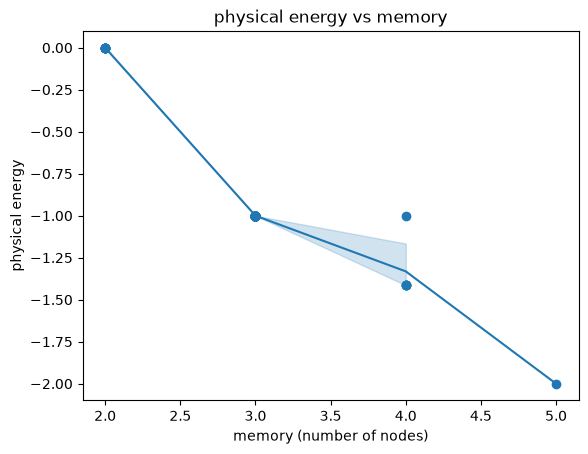

In [90]:
final_states_df = pd.DataFrame(final_states)
final_states_df = final_states_df[final_states_df["end_temp"] == .1]
final_states_df = final_states_df[final_states_df["lambda"] == 0.5]

plt.scatter(final_states_df["memory"], final_states_df["energy"])
sns.lineplot(x=final_states_df["memory"], y=final_states_df["energy"])
plt.title("physical energy vs memory")
plt.xlabel("memory (number of nodes)")
plt.ylabel("physical energy")
plt.show()

Text(0.5, 1.0, 'energy over time')

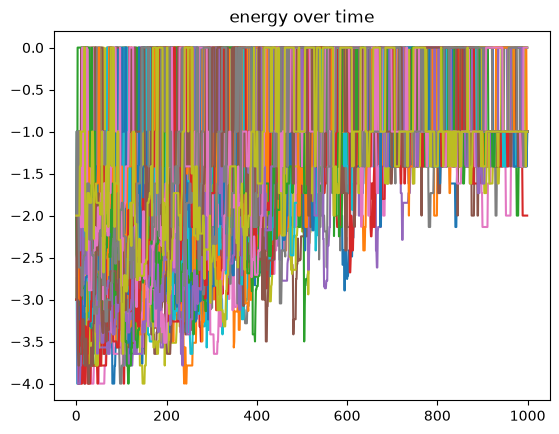

In [38]:
for index, row in instances.iterrows():
    if not Path(row["out_file"]).exists():
        continue

    this_data = pd.read_csv(row["out_file"])

    plt.plot(this_data.index, this_data["energy"], label=f"$\\lambda={row["lambda"]}$")

plt.title("energy over time")
# plt.legend()

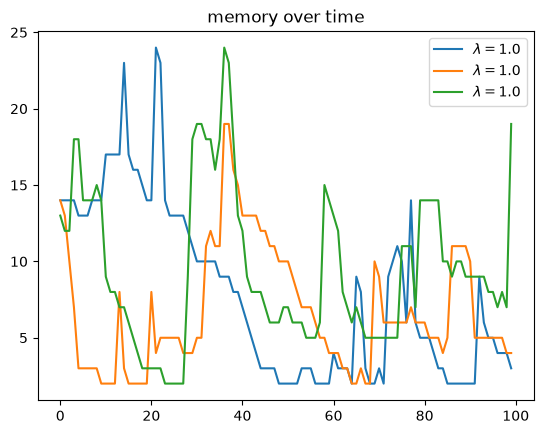

In [127]:
for index, row in instances.iterrows():
    if not Path(row["out_file"]).exists():
        continue

    if not index in keep_indices:
        continue

    this_data = pd.read_csv(row["out_file"])

    plt.plot(this_data.index, this_data["memory"], label=f"$\\lambda={row["lambda"]}$")

plt.title("memory over time")
plt.legend()